# True ball is an explosion

*NFL Big Data Bowl 2027: Combine to NFL Performance*

Football is an explosion sport. Every snap starts from rest and asks a body to turn stored energy into motion as fast as it can. The Combine measures that, but scouts read it as stopwatch times graded against a position curve: a 4.45 forty is elite for a tackle and ordinary for a corner.

We read it as **physics** instead. The 10 Hz sensor trace of the 40, the jumps and the bench become **joules**: the explosive energy each prospect's body produced. Then we follow 510 prospects from the 2023–2025 classes (WR, TE, DB, OL, DL) into regular-season game tracking and ask three questions:

1. Does Combine explosion show up on the field?
2. Does it predict who plays **beyond what the draft slot already says**?
3. Where does the draft get it wrong?

**Short answer:** explosion is real on the field, the draft prices it in on average, and it **misses the explosive tail**. The most explosive fifth of each position group and class outplays its draft slot far more often than everyone else, and on the defensive line the chain runs all the way from the Combine start to the game get-off to pressure on the quarterback.

In [1]:
import polars as pl
from IPython.display import Image, display

from eeg import config
from eeg.config import PROJECT_ROOT
from eeg.viz import figures as F

F._style()
cfg = config.load()
interim, processed = PROJECT_ROOT / "data/interim", PROJECT_ROOT / "data/processed"
out = PROJECT_ROOT / "reports/figures"
mismatch = pl.read_parquet(processed / "mismatch.parquet")

## 1. The explosion, in joules

Each Combine drill becomes the mechanical energy it took:

- **40-yard dash (10 Hz tracking).** We fit the sensor speed trace to $v(t) = v_{max}\,(1 - e^{-(t - t_0)/\tau})$ and take the kinetic energy at top speed, $\tfrac12 m v_{max}^2$, plus the work done against air drag.
- **Vertical jump:** $m g h$. **Broad jump:** the take-off energy of a projectile that lands at that distance. **Bench:** reps × bar weight × lift height (arm length).

Each channel is scored against the prospect's own Combine class, and **total explosive energy** is the mean of those scores. It is deliberately *absolute*: a 330-lb tackle who moves like a 250-lb end carries far more energy, and the game rewards that energy.

Byron Young is the example. His tracked 40 peaked at 11.1 m/s, nearly 7,000 J of kinetic energy at 113 kg, almost three standard deviations above his class. The draft took him 77th, a slot that typically earns about 280 snaps a season in his group. He has played 889.

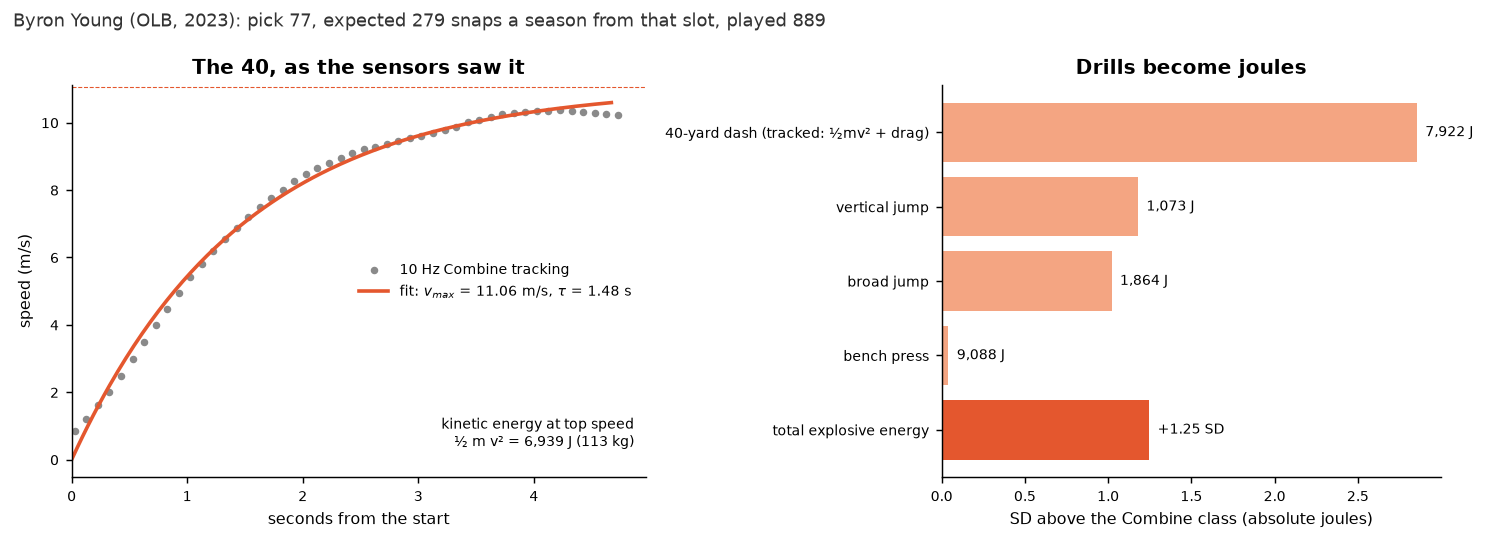

In [2]:
ex = cfg["figures"]["example_prospect"]["player_id"]
m = mismatch.filter(pl.col("player_id") == ex).row(0, named=True)
label = (f"{m['name']} ({m['pos']}, {m['draft_year']}): pick {m['draft_overall_pick']}, "
         f"expected {m['expected_snaps_per_season']:.0f} snaps a season from that slot, played {m['scrim_per_season']:.0f}")
F.fig_physics(interim, processed, out / "final_1_physics.png", ex, label, cfg)
display(Image(out / "final_1_physics.png"))

## 2. The Combine shows up on Sundays, and the draft knows it

We measure the same physics in games: each player's top speed and burst from rest after the snap, per season, using a fixed-size sample of plays so a starter is not credited for simply playing more. Within each position group, the Combine predicts **game top speed** (cross-validated R² 0.31) and **game burst** (0.24). The explosion is real.

But teams know it too. For **playing time** (snaps per season, zero for players who never got on the field), draft slot alone explains 0.47 out of sample, and adding the Combine explains 0.46. On average, the Combine adds nothing the draft has not already priced in.

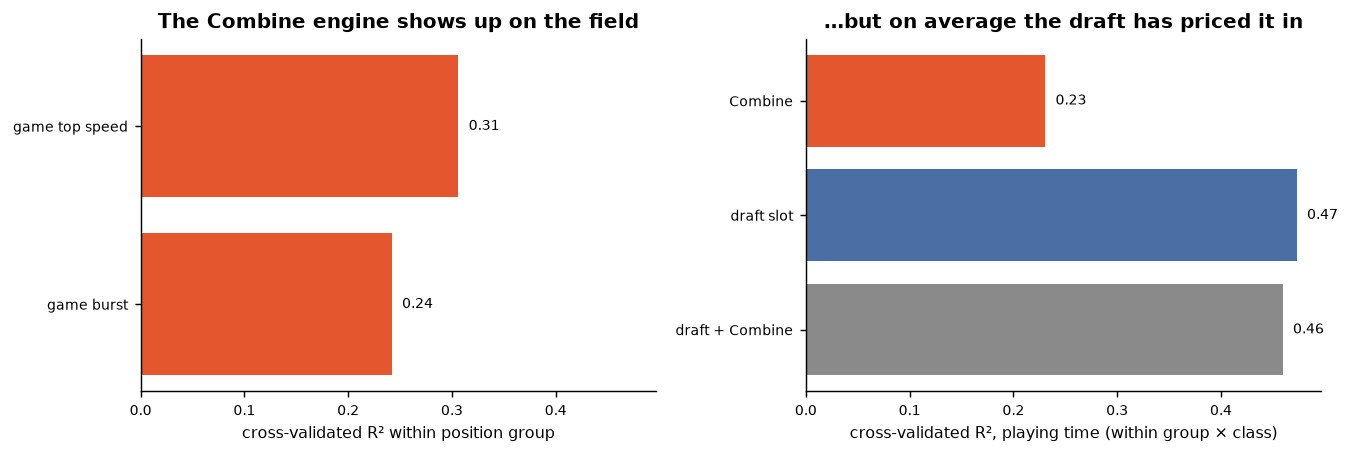

In [3]:
F.fig_priced(interim, processed, out / "final_2_priced.png", cfg)
display(Image(out / "final_2_priced.png"))

## 3. Where the draft misses: the explosive tail

An average can hide a tail. So we ask a scouting question instead: **for each prospect, how many snaps does his draft slot predict, and does he beat it?**

The expectation comes from the pick alone, fitted within each position group with a separate baseline for each class, so "linemen play every snap" and "rookies play less" are built in. Each prospect is left out of his own expectation. About half of all prospects beat their slot, as they should.

Then we take the **top 20% by total explosive energy** within each position group and class:

- They beat their slot **65%** of the time (95% CI 54–74%), against **50%** for everyone else (permutation p 0.026). For **games started**, 57% against 38% (p 0.004).
- It is a **tail effect**. The next four fifths all sit at 48–54%. Explosion doesn't help a little everywhere; the very top of it is what the draft under-rates.
- It is **not size**. The heaviest 20% beat their slot 54% of the time.
- It **holds across every check** we ran: tails of 10%, 20% or 30%, four different ways to set the draft expectation, each draft class on its own, and each position group left out. The defensive line carries the most of it; without DL the tail still leads, 57% against 48%.
- The **10 Hz tracked 40 energy alone** gets most of the way (63% against 51%). The jumps and bench add the rest.

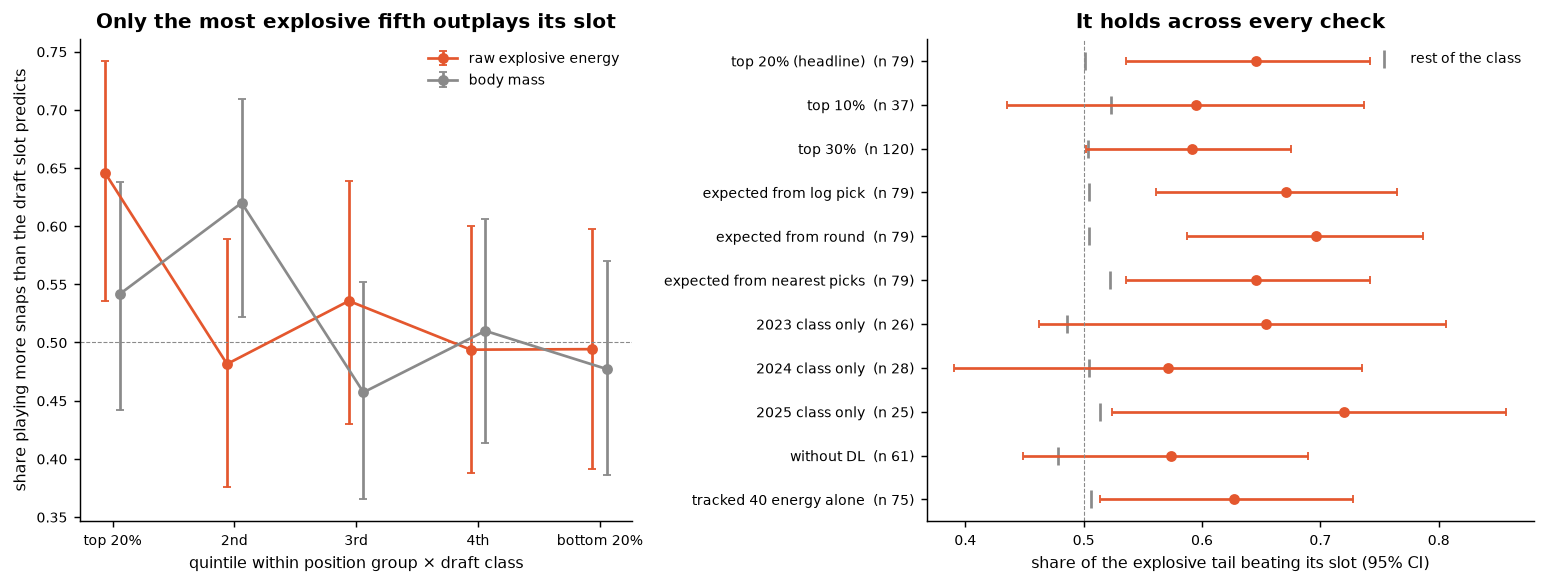

In [4]:
F.fig_tail(interim, processed, out / "final_3_tail.png", cfg)
display(Image(out / "final_3_tail.png"))

The players behind the number. These are the explosive-tail prospects with the most extra snaps per season over their draft slot:

In [5]:
tail = (
    mismatch.filter(pl.col("q_TEE_z_abs") <= 0.2)
    .with_columns((pl.col("scrim_per_season") - pl.col("expected_snaps_per_season")).alias("extra"))
    .sort("extra", descending=True)
    .head(10)
    .select(
        pl.col("name").alias("Player"), pl.col("pos").alias("Pos"), pl.col("draft_year").alias("Class"),
        pl.col("draft_overall_pick").cast(pl.String).fill_null("UDFA").alias("Pick"),
        pl.col("expected_snaps_per_season").round(0).cast(pl.Int64).alias("Expected snaps / season"),
        pl.col("scrim_per_season").round(0).cast(pl.Int64).alias("Actual snaps / season"),
    )
)
tail.to_pandas().style.hide(axis="index")

Player,Pos,Class,Pick,Expected snaps / season,Actual snaps / season
Elic Ayomanor,WR,2025,136,113,787
Byron Young,OLB,2023,77,279,889
Anthony Bradford,G,2023,108,170,758
Jared Wilson,G,2025,95,247,784
Chamarri Conner,SS,2023,119,156,632
Theo Johnson,TE,2024,107,334,776
Jalen Coker,WR,2024,UDFA,2,434
YaYa Diaby,OLB,2023,82,262,694
Michael Wilson,WR,2023,94,440,818
Marques Sigle,SS,2025,160,49,387


Elic Ayomanor (pick 136, 14 starts as a rookie) and Byron Young (pick 77, 16 starts a season) became every-down players. Anthony Bradford (pick 108) and Jared Wilson (pick 95), mid-round guards, start about 13 games a season. Jalen Coker went undrafted and played over 400 snaps a season. The tail misses too, and the misses are real: Troy Fautanu and Deonte Banks were first-round picks who played well short of that slot. The tail is a better bet than its draft slot, not a sure thing.

The same tail also **leaves the league less** than its slot predicts: 6 exits where the draft model expects 9.6. With three seasons and 48 exits in total, that is a direction, not a proof.

## 4. Up front, explosion is the job

On the defensive line every snap is a sprint start from a stance, and that is exactly what the 40's first 10 yards measure. We express the official 10-yard split as the mean acceleration it implies, $a_{10} = 2 d / t^2$, and follow it into the game through **get-off**: the competition's per-play get-off time for each rusher, in seconds from the snap (lower is faster).

Within each NFL position (DE, OLB, DT and NT compared only with their own), and beyond the draft slot and snaps played:

- A faster Combine start means a **faster get-off** (β −0.44, CI −0.68 to −0.20).
- A faster get-off means a **higher pressure rate** (β −0.47, CI −0.67 to −0.27).
- The start predicts pressure (β 0.36) and shrinks to 0.20 once get-off is in the model: **the Combine start reaches the quarterback through the get-off.**

The sign holds in every draft class; the 2025 class, with only its rookie season, is the weakest.

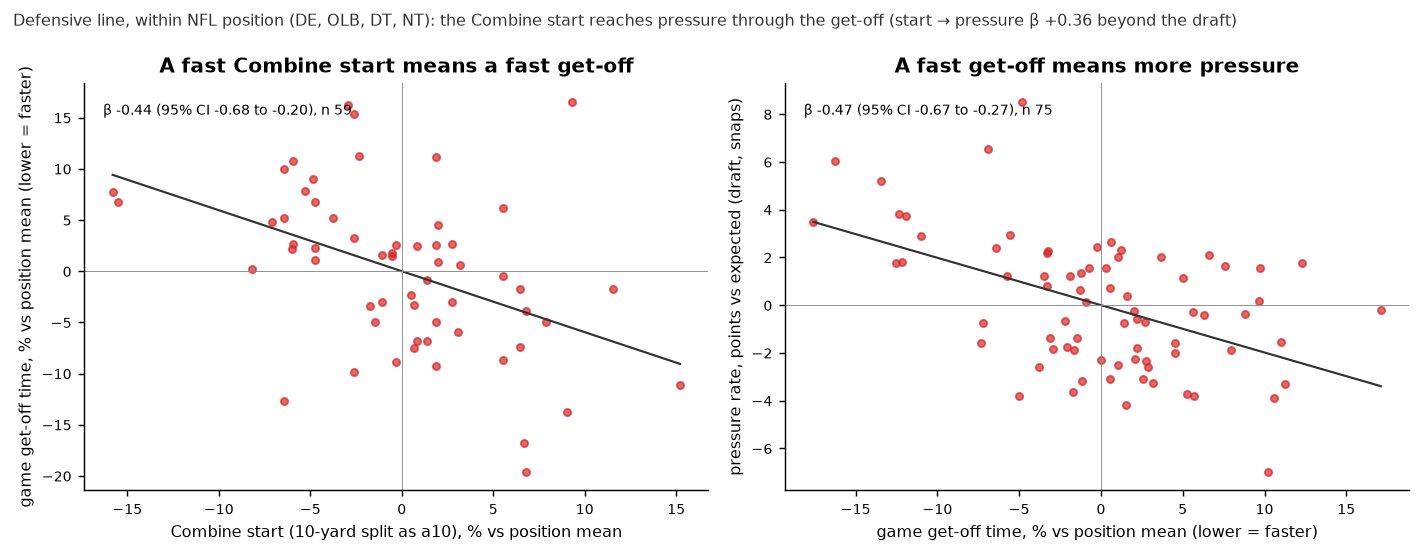

In [6]:
F.fig_dl_chain(interim, processed, out / "final_4_dl_chain.png", cfg)
display(Image(out / "final_4_dl_chain.png"))

## 5. How much of the 40 reaches the game

Finally, the ratio we set out to build: **game top speed as a share of Combine top speed**. Receivers reach 83% of their 40 in games, defensive backs 78%, tight ends 79%, defensive linemen 69% and offensive linemen 58%. That is a useful development benchmark for each room.

Within a group, though, bigger engines reach a *smaller* share (r −0.27): game speeds bunch together, so the fastest Combine runners lose the most. The share is reliable season to season, but it adds nothing to playing time or production beyond the draft. **What the draft misses is the size of the explosion, not the fraction that reaches the field.**

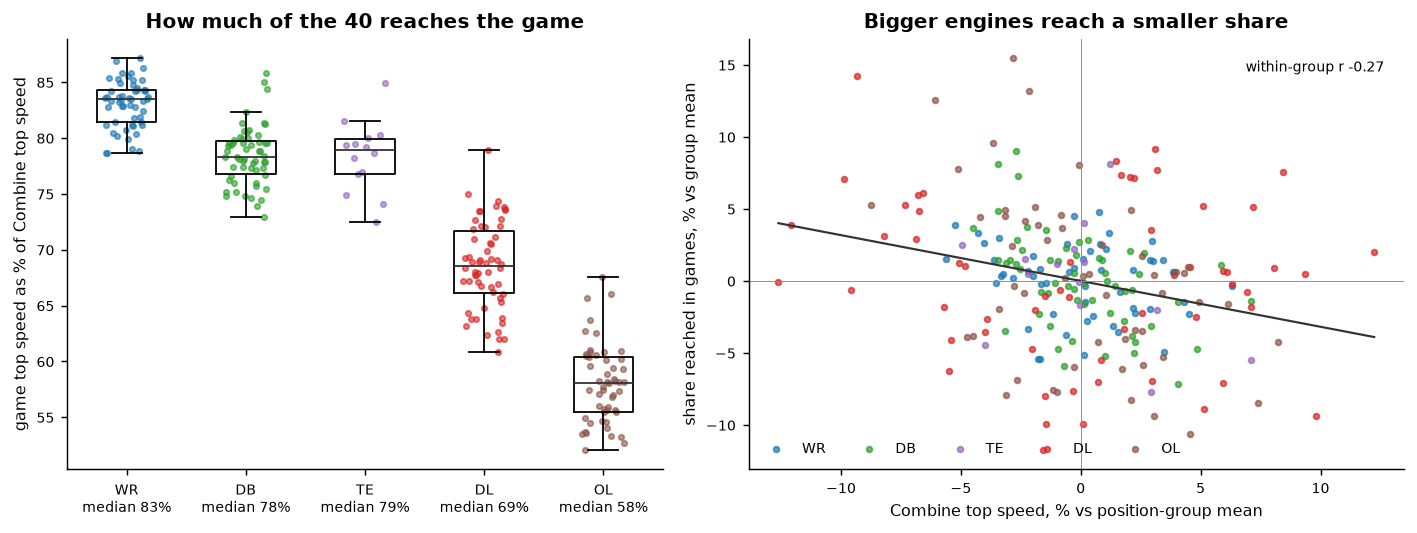

In [7]:
F.fig_eta(processed, interim, out / "final_5_eta.png")
display(Image(out / "final_5_eta.png"))

## What scouts and coaches can do with this

1. **Flag the explosive tail.** Rank each position group's class by total explosive energy and mark the top fifth. In the middle and late rounds, and among undrafted free agents, those players are better bets than their slot: they play more, start more, and tend to stay in the league longer.
2. **On the defensive line, weight the 10-yard split.** It predicts get-off, and get-off predicts pressure, beyond what the draft already knows. It is one number scouts already have, read as physics.
3. **Train get-off.** It is the link between Combine explosion and production for pass rushers, it is measured on every snap, and it is stable season to season (retest 0.84).
4. **Don't pay twice for the average Combine.** Outside the tail, the draft has already priced the workout.
5. **Use the share of the 40 that reaches the game as a benchmark by position**, not as a ranking: it tells a coach what top speed to expect from a player in games, not who will play.

## Limits

Three draft classes and five position groups (no QB, RB or LB in the data). Receiver and tight-end play data cover routes only. Tenure is early: at most three seasons. We ran many checks on one dataset, and the headline holds in all of them, but the effect is moderate and its strongest part sits on the defensive line.

## Method and code

All statistics are within position group; positions only define the comparison and are never a model input. The draft control is the overall pick plus an undrafted indicator. P-values come from permutations within position group × class. Game values use the expected best-3 of 50 random plays per season, so they don't grow with playing time. Code, tests and full reports: the project repository (`src/eeg`, `reports/`).